### pan_cancer 六分类

In [2]:
import pandas as pd
import os
# 加载数据集
file_path = '../ELIFE pancancer ready-to-use data.csv'
data = pd.read_csv(file_path)

In [9]:
positive_samples_Breast = data[data['Diagnosis'] == "Breast cancer"]
positive_samples_CRC = data[data['Diagnosis'] == "CRC cancer"]
positive_samples_Gastric = data[data['Diagnosis'] == "Gastric cancer"]
positive_samples_Liver = data[data['Diagnosis'] == "Liver cancer"]
positive_samples_Lung = data[data['Diagnosis'] == "Lung cancer"]
negative_samples = data[data['Label'] == 0]

positive_samples_CRC_upsampled = positive_samples_CRC.sample(n=int(len(positive_samples_CRC)*1.5), replace=True, random_state=42)
positive_samples_Gastric_upsampled = positive_samples_Gastric.sample(n=int(len(positive_samples_Gastric)*2.5), replace=True, random_state=42)
positive_samples_Liver_upsampled = positive_samples_Liver.sample(n=len(positive_samples_Liver)*2, replace=True, random_state=42)
positive_samples_Lung_upsampled = positive_samples_Lung.sample(n=len(positive_samples_Lung)*2, replace=True, random_state=42)

num_negative = round((len(positive_samples_Breast)+len(positive_samples_CRC_upsampled)+len(positive_samples_Gastric_upsampled)+len(positive_samples_Liver_upsampled)+len(positive_samples_Lung_upsampled))/5)  # 负样本数量是正样本的 1 倍
negative_samples = negative_samples.sample(n=num_negative, random_state=42)  # 随机采样负样本

# 合并正负样本
pan_sample = pd.concat([positive_samples_Breast, positive_samples_CRC_upsampled, positive_samples_Gastric_upsampled,positive_samples_Liver_upsampled, positive_samples_Lung_upsampled, negative_samples], ignore_index=True)
pan_sample = pan_sample.drop(columns=["SampleID", "Cohort", "Label"])
pan_sample.to_csv("pan_sample_6.csv", index=False)

In [10]:
pan_data6 = pd.read_csv("pan_sample_6.csv")
pan_data6

,Diagnosis,TMD_1,TMD_2,TMD_3,TMD_4,TMD_5,TMD_6,TMD_7,TMD_8,TMD_9,...,MOTIF_END_TTCG,MOTIF_END_TTCT,MOTIF_END_TTGA,MOTIF_END_TTGC,MOTIF_END_TTGG,MOTIF_END_TTGT,MOTIF_END_TTTA,MOTIF_END_TTTC,MOTIF_END_TTTG,MOTIF_END_TTTT
0,Breast cancer,0.965447,0.134228,0.051155,0.141777,0.995098,0.942529,0.968254,0.300000,0.140625,...,0.000351,0.004416,0.003916,0.002454,0.003231,0.003478,0.005930,0.004735,0.004640,0.008361
1,Breast cancer,0.960526,0.052632,0.046954,0.070341,0.931122,0.943966,1.000000,0.194313,0.214182,...,0.000362,0.004477,0.003920,0.002485,0.003396,0.003507,0.005892,0.004876,0.004640,0.008428
2,Breast cancer,0.977358,0.162791,0.035363,0.179856,0.971193,0.909091,0.928571,0.367412,0.162437,...,0.000351,0.004417,0.003934,0.002483,0.003176,0.003516,0.006063,0.004917,0.004646,0.008551
3,Breast cancer,0.971576,0.194444,0.027308,0.098697,0.952586,0.902299,1.000000,0.211806,0.115493,...,0.000352,0.004391,0.003840,0.002459,0.003224,0.003470,0.005855,0.004802,0.004518,0.008331
4,Breast cancer,0.695946,0.138132,0.176598,0.223963,0.926108,0.878049,0.977528,0.293173,0.397436,...,0.000372,0.004394,0.004086,0.002530,0.003478,0.003566,0.005995,0.004805,0.004723,0.008305
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1461,Control,0.959786,0.166667,0.005926,0.061905,0.942424,0.941176,0.985294,0.186111,0.154519,...,0.000398,0.004626,0.004053,0.002617,0.003383,0.003727,0.005972,0.004914,0.004852,0.008759
1462,Control,0.943574,0.034091,0.092105,0.072797,0.993976,0.724638,0.954545,0.163636,0.127358,...,0.000408,0.004653,0.004081,0.002567,0.003417,0.003734,0.006317,0.005218,0.004940,0.008859
1463,Control,0.985222,0.000000,0.023392,0.058139,0.842424,0.951219,1.000000,0.254545,0.189189,...,0.000359,0.004352,0.004080,0.002531,0.003492,0.003504,0.005623,0.004527,0.004813,0.007876
1464,Control,0.960452,0.143885,0.085506,0.150826,0.924528,0.940476,1.000000,0.334783,0.310757,...,0.000382,0.004779,0.003962,0.002596,0.003246,0.003681,0.006025,0.005025,0.004728,0.008939


In [11]:
test = pan_data6['Diagnosis']
import numpy as np
unique_values, counts = np.unique(test, return_counts=True)
for value, count in zip(unique_values, counts):
    print(f"Label {value} has {count} samples")

Label Breast cancer has 223 samples
Label CRC cancer has 238 samples
Label Control has 244 samples
Label Gastric cancer has 245 samples
Label Liver cancer has 244 samples
Label Lung cancer has 272 samples


In [12]:
# 定义标签映射字典
label_mapping = {
    'Control': 0,
    'Breast cancer': 1,
    'CRC cancer': 2,
    'Gastric cancer': 3,
    'Liver cancer': 4,
    'Lung cancer': 5
}

# 将 Diagnosis 列映射为数字标签
pan_data6['Diagnosis'] = pan_data6['Diagnosis'].map(label_mapping)

# 将列名 Diagnosis 改为 Label
pan_data6.rename(columns={'Diagnosis': 'Label'}, inplace=True)

# 保存为新文件
pan_data6.to_csv('pan_sample_6_labeled.csv', index=False)

In [13]:
data = pd.read_csv('pan_sample_6_labeled.csv')
data

,Label,TMD_1,TMD_2,TMD_3,TMD_4,TMD_5,TMD_6,TMD_7,TMD_8,TMD_9,...,MOTIF_END_TTCG,MOTIF_END_TTCT,MOTIF_END_TTGA,MOTIF_END_TTGC,MOTIF_END_TTGG,MOTIF_END_TTGT,MOTIF_END_TTTA,MOTIF_END_TTTC,MOTIF_END_TTTG,MOTIF_END_TTTT
0,1,0.965447,0.134228,0.051155,0.141777,0.995098,0.942529,0.968254,0.300000,0.140625,...,0.000351,0.004416,0.003916,0.002454,0.003231,0.003478,0.005930,0.004735,0.004640,0.008361
1,1,0.960526,0.052632,0.046954,0.070341,0.931122,0.943966,1.000000,0.194313,0.214182,...,0.000362,0.004477,0.003920,0.002485,0.003396,0.003507,0.005892,0.004876,0.004640,0.008428
2,1,0.977358,0.162791,0.035363,0.179856,0.971193,0.909091,0.928571,0.367412,0.162437,...,0.000351,0.004417,0.003934,0.002483,0.003176,0.003516,0.006063,0.004917,0.004646,0.008551
3,1,0.971576,0.194444,0.027308,0.098697,0.952586,0.902299,1.000000,0.211806,0.115493,...,0.000352,0.004391,0.003840,0.002459,0.003224,0.003470,0.005855,0.004802,0.004518,0.008331
4,1,0.695946,0.138132,0.176598,0.223963,0.926108,0.878049,0.977528,0.293173,0.397436,...,0.000372,0.004394,0.004086,0.002530,0.003478,0.003566,0.005995,0.004805,0.004723,0.008305
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1461,0,0.959786,0.166667,0.005926,0.061905,0.942424,0.941176,0.985294,0.186111,0.154519,...,0.000398,0.004626,0.004053,0.002617,0.003383,0.003727,0.005972,0.004914,0.004852,0.008759
1462,0,0.943574,0.034091,0.092105,0.072797,0.993976,0.724638,0.954545,0.163636,0.127358,...,0.000408,0.004653,0.004081,0.002567,0.003417,0.003734,0.006317,0.005218,0.004940,0.008859
1463,0,0.985222,0.000000,0.023392,0.058139,0.842424,0.951219,1.000000,0.254545,0.189189,...,0.000359,0.004352,0.004080,0.002531,0.003492,0.003504,0.005623,0.004527,0.004813,0.007876
1464,0,0.960452,0.143885,0.085506,0.150826,0.924528,0.940476,1.000000,0.334783,0.310757,...,0.000382,0.004779,0.003962,0.002596,0.003246,0.003681,0.006025,0.005025,0.004728,0.008939


### Fscore

In [102]:
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
import matplotlib.pyplot as plt
from sklearn.utils.class_weight import compute_class_weight
file_path = "pan_sample_6_labeled_FscoreSorted.csv"
data = pd.read_csv(file_path)

In [103]:
data

,class,GWMD_chr1_192,GWMD_chr13_107,GWMD_chr1_191,GWMD_chr5_101,GWMD_chr8_115,GWMD_chr2_222,TMD_307,GWMD_chr8_116,GWMD_chr5_89,...,CNA_1:8000001-9000000,CNA_19:3000001-4000000,CNA_7:115000001-116000000,GWFP_long_12:20000001-25000000,CNA_3:86000001-87000000,GWFP_total_12:20000001-25000000,TMD_212,CNA_7:117000001-118000000,CNA_8:128000001-129000000,CNA_4:90000001-91000000
0,1,0.876812,0.856268,0.829649,0.834187,0.774291,0.819776,0.000000,0.821152,0.840395,...,0.999818,1.018160,1.06926,0.494430,0.959492,0.544431,0.234234,1.11491,0.995860,1.019080
1,1,0.854706,0.845200,0.785690,0.799822,0.733747,0.838455,0.002419,0.815664,0.806911,...,0.955025,1.004800,1.02301,0.417070,0.949734,0.449435,0.128571,1.10621,1.038630,0.992447
2,1,0.843885,0.837972,0.783861,0.813564,0.771333,0.824288,0.000000,0.808723,0.834145,...,1.018860,1.019780,1.04379,0.580662,0.974472,0.624901,0.231579,1.06401,1.009950,1.012320
3,1,0.871203,0.860109,0.814638,0.834249,0.764535,0.839784,0.000000,0.846843,0.857588,...,1.023900,1.069910,1.03893,0.593301,0.945364,0.627225,0.205556,1.07670,0.983673,1.002070
4,1,0.886208,0.841958,0.832209,0.839638,0.734862,0.831520,0.301539,0.834807,0.746778,...,1.021070,1.002760,1.07797,0.673954,0.936014,0.698939,0.266409,1.09507,1.038530,1.044710
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1308,0,0.880597,0.854135,0.818539,0.806291,0.755228,0.845229,0.075975,0.844516,0.824807,...,0.985240,1.018600,1.05464,0.518950,0.962983,0.556799,0.288235,1.07701,0.998067,0.994982
1309,0,0.843968,0.839747,0.797606,0.808639,0.787805,0.831027,0.000000,0.825614,0.846972,...,1.008100,1.023230,1.05563,0.755020,0.935185,0.761389,0.105263,1.07877,1.050900,0.945840
1310,0,0.875127,0.847982,0.783499,0.827751,0.784985,0.846800,0.000000,0.810090,0.854077,...,0.997421,0.991137,1.02808,0.565188,0.966132,0.539231,0.090452,1.05588,1.029240,0.988143
1311,0,0.871177,0.851436,0.819438,0.799631,0.776234,0.818276,0.017893,0.834107,0.848613,...,0.960028,1.022690,1.05475,0.529906,0.948359,0.536418,0.176471,1.07659,1.005700,0.963169


In [105]:
# 分离特征和标签
X = data.drop(columns=['class'])  # 特征列
y = data['class']  # 标签列

# 数据分割：将数据集分为训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [106]:
all_features = X_train.columns.tolist()
auc_train_scores_Fscore = []
auc_val_scores_Fscore = []
best_auc = 0
best_feature_count = 0
best_X_train = None
best_X_test = None
best_X_val = None
prev_val_auc = 0
max_auc_diff = 0.2

# 连续超过阈值的计数器
overfit_count = 0
decline_count = 0

# 设置连续次数阈值
max_overfit_tolerance = 10
max_decline_tolerance = 5

In [107]:
for i in range(1, len(all_features) + 1):
    selected_features = all_features[:i]  # 前 i 个特征

    # # 计算样本权重（基于训练集）
    # classes = np.unique(y_train)
    # class_weights = compute_class_weight('balanced', classes=classes, y=y_train)
    # sample_weights = np.array([class_weights[i] for i in y_train])

    # 构造 DMatrix 数据
    dtrain = xgb.DMatrix(X_train[selected_features], label=y_train)
    dval = xgb.DMatrix(X_val[selected_features], label=y_val)
    dtest = xgb.DMatrix(X_test[selected_features], label=y_test)

    # 多分类 XGBoost 参数
    params = {
        'booster': 'gbtree',
        'objective': 'multi:softprob',   # 输出每类概率
        'num_class': 6,                  # 六分类
        'eval_metric': 'mlogloss',
        'max_depth': 4,
        'lambda': 3,
        'alpha': 0.2,
        'subsample': 0.75,
        'colsample_bytree': 0.75,
        'min_child_weight': 6,
        # 'eta': 0.025,
        'seed': 0,
        'nthread': 8,
        'gamma': 0.2,
        'learning_rate': 0.05
    }

    watchlist = [(dtrain, 'train'), (dval, 'eval')]

    # 模型训练
    model = xgb.train(params, dtrain, num_boost_round=50, evals=watchlist, early_stopping_rounds=10, verbose_eval=False)

    # 获取预测概率
    y_pred_train_prob = model.predict(dtrain)
    y_pred_val_prob = model.predict(dval)

    # AUC（One-vs-Rest 多分类）
    auc_train = roc_auc_score(y_train, y_pred_train_prob, multi_class='ovr', average='weighted')
    auc_val = roc_auc_score(y_val, y_pred_val_prob, multi_class='ovr', average='weighted')

    # 记录分数
    auc_train_scores_Fscore.append(auc_train)
    auc_val_scores_Fscore.append(auc_val)

    print(f"当前特征数: {i} | Val AUC: {auc_val:.4f}, Train AUC: {auc_train:.4f}")

    if i >200:
        break

    # 过拟合判断
    if (auc_train - auc_val) > max_auc_diff:
        overfit_count += 1
        print(f"过拟合检测：训练集 AUC={auc_train:.4f}, 验证集 AUC={auc_val:.4f}，连续次数：{overfit_count}")
        if overfit_count >= max_overfit_tolerance:
            print(f"过拟合连续超过 {max_overfit_tolerance} 次，停止特征增加！")
            break
    else:
        overfit_count = 0

    # 验证集 AUC 下降判断
    if auc_val < prev_val_auc:
        decline_count += 1
        print(f"验证集 AUC 开始下降（{prev_val_auc:.4f} → {auc_val:.4f}），连续次数：{decline_count}")
        if decline_count >= max_decline_tolerance:
            print(f"验证集 AUC 连续下降超过 {max_decline_tolerance} 次，停止特征增加！")
            break
    else:
        decline_count = 0

   # 记录当前最优特征集
    if auc_val > best_auc:
        best_auc = auc_val
        train_p = auc_train
        best_feature_count = i
        best_X_train = X_train[selected_features].copy()
        best_X_test = X_test[selected_features].copy()
        best_X_val = X_val[selected_features].copy()
        
    # 记录上一次的验证集 AUC
    prev_val_auc = auc_val

# 输出最佳特征数
print(f"选择的特征数: {best_feature_count}, 最佳验证集 AUC: {best_auc:.4f}, 对应的训练集 AUC：{train_p:.4f}")

当前特征数: 1 | Val AUC: 0.6781, Train AUC: 0.7799
当前特征数: 2 | Val AUC: 0.6984, Train AUC: 0.8176
当前特征数: 3 | Val AUC: 0.7209, Train AUC: 0.8510
当前特征数: 4 | Val AUC: 0.7279, Train AUC: 0.8763
当前特征数: 5 | Val AUC: 0.7365, Train AUC: 0.8908
当前特征数: 6 | Val AUC: 0.7633, Train AUC: 0.9037
当前特征数: 7 | Val AUC: 0.7709, Train AUC: 0.9114
当前特征数: 8 | Val AUC: 0.7821, Train AUC: 0.9207
当前特征数: 9 | Val AUC: 0.7907, Train AUC: 0.9282
当前特征数: 10 | Val AUC: 0.7895, Train AUC: 0.9297
验证集 AUC 开始下降（0.7907 → 0.7895），连续次数：1
当前特征数: 11 | Val AUC: 0.7982, Train AUC: 0.9350
当前特征数: 12 | Val AUC: 0.8056, Train AUC: 0.9415
当前特征数: 13 | Val AUC: 0.8157, Train AUC: 0.9444
当前特征数: 14 | Val AUC: 0.8157, Train AUC: 0.9479
验证集 AUC 开始下降（0.8157 → 0.8157），连续次数：1
当前特征数: 15 | Val AUC: 0.8212, Train AUC: 0.9506
当前特征数: 16 | Val AUC: 0.8270, Train AUC: 0.9523
当前特征数: 17 | Val AUC: 0.8250, Train AUC: 0.9525
验证集 AUC 开始下降（0.8270 → 0.8250），连续次数：1
当前特征数: 18 | Val AUC: 0.8379, Train AUC: 0.9549
当前特征数: 19 | Val AUC: 0.8248, Train AUC: 0.9565
验证集 A

In [80]:
pan_sample_FscoreSorted = pd.read_csv("pan_sample_6_labeled_FscoreSorted.csv")
pan_sample_FscoreSorted_selected94 = pan_sample_FscoreSorted.iloc[:, :95]
pan_sample_FscoreSorted_selected94.to_csv("../Fscore/pan_sample_6_labeled_FscoreSorted_selected94.csv", index=False)

In [90]:
import pandas as pd

# 保存训练集和验证集的 AUC 到 CSV
auc_df = pd.DataFrame({
    "Num_Features": range(1, len(auc_train_scores_Fscore) + 1),
    "Train_AUC": auc_train_scores_Fscore,
    "Validation_AUC": auc_val_scores_Fscore
})

auc_df.to_csv("AUC_scores_Fscore6.csv", index=False)

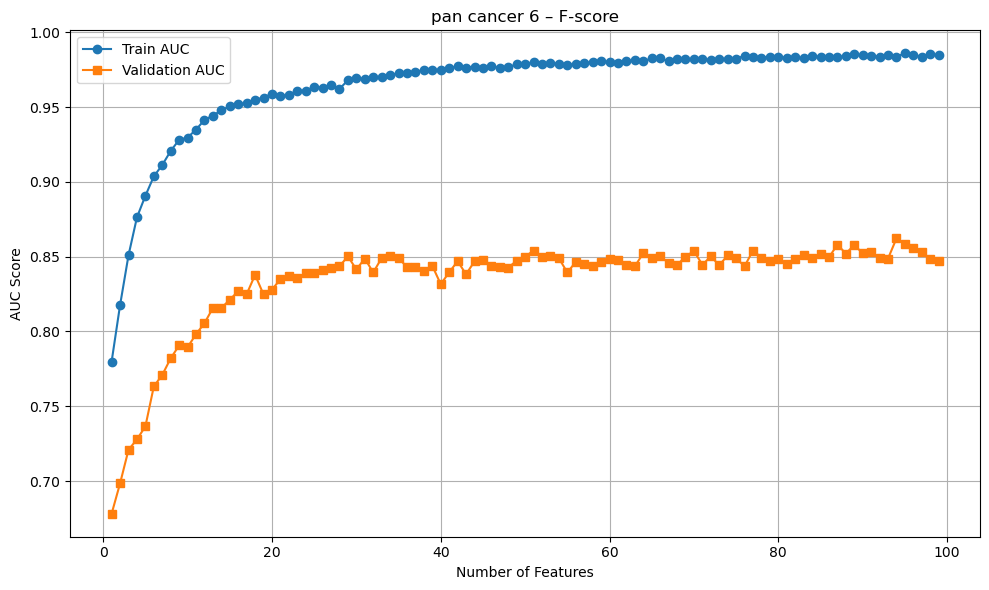

In [91]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取 CSV 文件
auc_df = pd.read_csv("AUC_scores_Fscore6.csv")

# 绘制图像
plt.figure(figsize=(10, 6))
plt.plot(auc_df["Num_Features"], auc_df["Train_AUC"], label='Train AUC', marker='o')
plt.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], label='Validation AUC', marker='s')

plt.xlabel("Number of Features")
plt.ylabel("AUC Score")
plt.title("pan cancer 6 – F-score")
plt.legend()
plt.grid(True)
plt.tight_layout()

# 保存图像为 PNG 文件
plt.savefig("AUC_vs_FeatureCount_Fscore6.png", dpi=300)
plt.show()


### ANOVA

In [86]:
import pandas as pd

# 1. 读取最终的 CSV 文件
csv_file = "pan_sample_6_labeled_AnovaSorted.csv"
df = pd.read_csv(csv_file)

# 2. 读取 ANOVA 排序的特征文件，获取正确的特征名顺序
anova_sorted_file = "../ANOVA/pan_6_feature_importance.csv" 
with open(anova_sorted_file, "r") as f:
    sorted_feature_names = [line.split()[1] for line in f.readlines()]  # 取出特征名称

# 3. 获取当前 CSV 文件的列名（去掉第一列 class）
original_column_names = list(df.columns[1:])  # 去掉第 1 列类别标签

# 4. 创建新的列名列表（保持类别标签不变）
new_column_names = ["class"] + sorted_feature_names[:len(original_column_names)]

# 5. 重新设置 DataFrame 的列名
df.columns = new_column_names

# 6. 保存修改后的 CSV 文件
df.to_csv("pan_sample_6_labeled_AnovaSorted_corrected.csv", index=False)


In [128]:
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
import matplotlib.pyplot as plt

file_path = "pan_sample_6_labeled_AnovaSorted_corrected.csv"
data = pd.read_csv(file_path)

In [129]:
data

,class,GWMD_chr1_192,GWMD_chr1_191,GWMD_chr5_101,GWMD_chr13_107,GWMD_chr2_222,GWMD_chr8_115,GWMD_chr5_89,GWMD_chr8_116,TMD_307,...,CNA_19:3000001-4000000,CNA_7:115000001-116000000,CNA_7:24000001-25000000,GWFP_long_12:20000001-25000000,CNA_3:86000001-87000000,GWFP_total_12:20000001-25000000,CNA_7:117000001-118000000,TMD_212,CNA_8:128000001-129000000,CNA_4:90000001-91000000
0,1,0.876812,0.829649,0.834187,0.856268,0.819776,0.774291,0.840395,0.821152,0.000000,...,1.018160,1.06926,1.06871,0.494430,0.959492,0.544431,1.11491,0.234234,0.995860,1.019080
1,1,0.854706,0.785690,0.799822,0.845200,0.838455,0.733747,0.806911,0.815664,0.002419,...,1.004800,1.02301,1.06022,0.417070,0.949734,0.449435,1.10621,0.128571,1.038630,0.992447
2,1,0.843885,0.783861,0.813564,0.837972,0.824288,0.771333,0.834145,0.808723,0.000000,...,1.019780,1.04379,1.03436,0.580662,0.974472,0.624901,1.06401,0.231579,1.009950,1.012320
3,1,0.871203,0.814638,0.834249,0.860109,0.839784,0.764535,0.857588,0.846843,0.000000,...,1.069910,1.03893,1.00824,0.593301,0.945364,0.627225,1.07670,0.205556,0.983673,1.002070
4,1,0.886208,0.832209,0.839638,0.841958,0.831520,0.734862,0.746778,0.834807,0.301539,...,1.002760,1.07797,1.02343,0.673954,0.936014,0.698939,1.09507,0.266409,1.038530,1.044710
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1308,0,0.880597,0.818539,0.806291,0.854135,0.845229,0.755228,0.824807,0.844516,0.075975,...,1.018600,1.05464,1.08352,0.518950,0.962983,0.556799,1.07701,0.288235,0.998067,0.994982
1309,0,0.843968,0.797606,0.808639,0.839747,0.831027,0.787805,0.846972,0.825614,0.000000,...,1.023230,1.05563,1.01761,0.755020,0.935185,0.761389,1.07877,0.105263,1.050900,0.945840
1310,0,0.875127,0.783499,0.827751,0.847982,0.846800,0.784985,0.854077,0.810090,0.000000,...,0.991137,1.02808,1.00315,0.565188,0.966132,0.539231,1.05588,0.090452,1.029240,0.988143
1311,0,0.871177,0.819438,0.799631,0.851436,0.818276,0.776234,0.848613,0.834107,0.017893,...,1.022690,1.05475,1.02665,0.529906,0.948359,0.536418,1.07659,0.176471,1.005700,0.963169


In [131]:
# 分离特征和标签
X = data.drop(columns=['class'])  # 特征列
y = data['class']  # 标签列

# 数据分割：将数据集分为训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [132]:
all_features = X_train.columns.tolist()
auc_train_scores_ANOVA = []
auc_val_scores_ANOVA = []
best_auc = 0
best_feature_count = 0
best_X_train = None
best_X_test = None
best_X_val = None
prev_val_auc = 0
max_auc_diff = 0.2

# 连续超过阈值的计数器
overfit_count = 0
decline_count = 0

# 设置连续次数阈值
max_overfit_tolerance = 10
max_decline_tolerance = 5

In [133]:
for i in range(1, len(all_features) + 1):
    selected_features = all_features[:i]  # 前 i 个特征

    # # 计算样本权重（基于训练集）
    # classes = np.unique(y_train)
    # class_weights = compute_class_weight('balanced', classes=classes, y=y_train)
    # sample_weights = np.array([class_weights[i] for i in y_train])

    # 构造 DMatrix 数据
    dtrain = xgb.DMatrix(X_train[selected_features], label=y_train)
    dval = xgb.DMatrix(X_val[selected_features], label=y_val)
    dtest = xgb.DMatrix(X_test[selected_features], label=y_test)

    # 多分类 XGBoost 参数
    params = {
        'booster': 'gbtree',
        'objective': 'multi:softprob',   # 输出每类概率
        'num_class': 6,                  # 六分类
        'eval_metric': 'mlogloss',
        'max_depth': 4,
        'lambda': 3,
        'alpha': 0.2,
        'subsample': 0.75,
        'colsample_bytree': 0.75,
        'min_child_weight': 6,
        # 'eta': 0.025,
        'seed': 0,
        'nthread': 8,
        'gamma': 0.2,
        'learning_rate': 0.05
    }

    watchlist = [(dtrain, 'train'), (dval, 'eval')]

    # 模型训练
    model = xgb.train(params, dtrain, num_boost_round=50, evals=watchlist, early_stopping_rounds=10, verbose_eval=False)

    # 获取预测概率
    y_pred_train_prob = model.predict(dtrain)
    y_pred_val_prob = model.predict(dval)

    # AUC（One-vs-Rest 多分类）
    auc_train = roc_auc_score(y_train, y_pred_train_prob, multi_class='ovr', average='weighted')
    auc_val = roc_auc_score(y_val, y_pred_val_prob, multi_class='ovr', average='weighted')

    # 记录分数
    auc_train_scores_ANOVA.append(auc_train)
    auc_val_scores_ANOVA.append(auc_val)

    print(f"当前特征数: {i} | Val AUC: {auc_val:.4f}, Train AUC: {auc_train:.4f}")

    if i >100:
        break

    # 过拟合判断
    if (auc_train - auc_val) > max_auc_diff:
        overfit_count += 1
        print(f"过拟合检测：训练集 AUC={auc_train:.4f}, 验证集 AUC={auc_val:.4f}，连续次数：{overfit_count}")
        if overfit_count >= max_overfit_tolerance:
            print(f"过拟合连续超过 {max_overfit_tolerance} 次，停止特征增加！")
            break
    else:
        overfit_count = 0

    # 验证集 AUC 下降判断
    if auc_val < prev_val_auc:
        decline_count += 1
        print(f"验证集 AUC 开始下降（{prev_val_auc:.4f} → {auc_val:.4f}），连续次数：{decline_count}")
        if decline_count >= max_decline_tolerance:
            print(f"验证集 AUC 连续下降超过 {max_decline_tolerance} 次，停止特征增加！")
            break
    else:
        decline_count = 0

   # 记录当前最优特征集
    if auc_val > best_auc:
        best_auc = auc_val
        train_p = auc_train
        best_feature_count = i
        best_X_train = X_train[selected_features].copy()
        best_X_test = X_test[selected_features].copy()
        best_X_val = X_val[selected_features].copy()
        
    # 记录上一次的验证集 AUC
    prev_val_auc = auc_val

# 输出最佳特征数
print(f"选择的特征数: {best_feature_count}, 最佳验证集 AUC: {best_auc:.4f}, 对应的训练集 AUC：{train_p:.4f}")

当前特征数: 1 | Val AUC: 0.6781, Train AUC: 0.7799
当前特征数: 2 | Val AUC: 0.7111, Train AUC: 0.8100
当前特征数: 3 | Val AUC: 0.7277, Train AUC: 0.8585
当前特征数: 4 | Val AUC: 0.7306, Train AUC: 0.8759
当前特征数: 5 | Val AUC: 0.7490, Train AUC: 0.8896
当前特征数: 6 | Val AUC: 0.7690, Train AUC: 0.9043
当前特征数: 7 | Val AUC: 0.7657, Train AUC: 0.9129
验证集 AUC 开始下降（0.7690 → 0.7657），连续次数：1
当前特征数: 8 | Val AUC: 0.7791, Train AUC: 0.9171
当前特征数: 9 | Val AUC: 0.7867, Train AUC: 0.9250
当前特征数: 10 | Val AUC: 0.7842, Train AUC: 0.9321
验证集 AUC 开始下降（0.7867 → 0.7842），连续次数：1
当前特征数: 11 | Val AUC: 0.7877, Train AUC: 0.9375
当前特征数: 12 | Val AUC: 0.7958, Train AUC: 0.9422
当前特征数: 13 | Val AUC: 0.8108, Train AUC: 0.9444
当前特征数: 14 | Val AUC: 0.8058, Train AUC: 0.9472
验证集 AUC 开始下降（0.8108 → 0.8058），连续次数：1
当前特征数: 15 | Val AUC: 0.8269, Train AUC: 0.9539
当前特征数: 16 | Val AUC: 0.8270, Train AUC: 0.9536
当前特征数: 17 | Val AUC: 0.8390, Train AUC: 0.9572
当前特征数: 18 | Val AUC: 0.8383, Train AUC: 0.9594
验证集 AUC 开始下降（0.8390 → 0.8383），连续次数：1
当前特征数: 19 | Val

In [ ]:
pan_sample_AnovaSorted_corrected = pd.read_csv("pan_sample_6_labeled_AnovaSorted_corrected.csv")
pan_sample_AnovaSorted_selected85 = pan_sample_AnovaSorted_corrected.iloc[:, :86]
pan_sample_AnovaSorted_selected85.to_csv("../ANOVA/pan_sample_6_labeled_AnovaSorted_selected85.csv", index=False)

In [134]:
import pandas as pd

# 保存训练集和验证集的 AUC 到 CSV
auc_df = pd.DataFrame({
    "Num_Features": range(1, len(auc_train_scores_ANOVA) + 1),
    "Train_AUC": auc_train_scores_ANOVA,
    "Validation_AUC": auc_val_scores_ANOVA
})

auc_df.to_csv("AUC_scores_ANOVA6.csv", index=False)

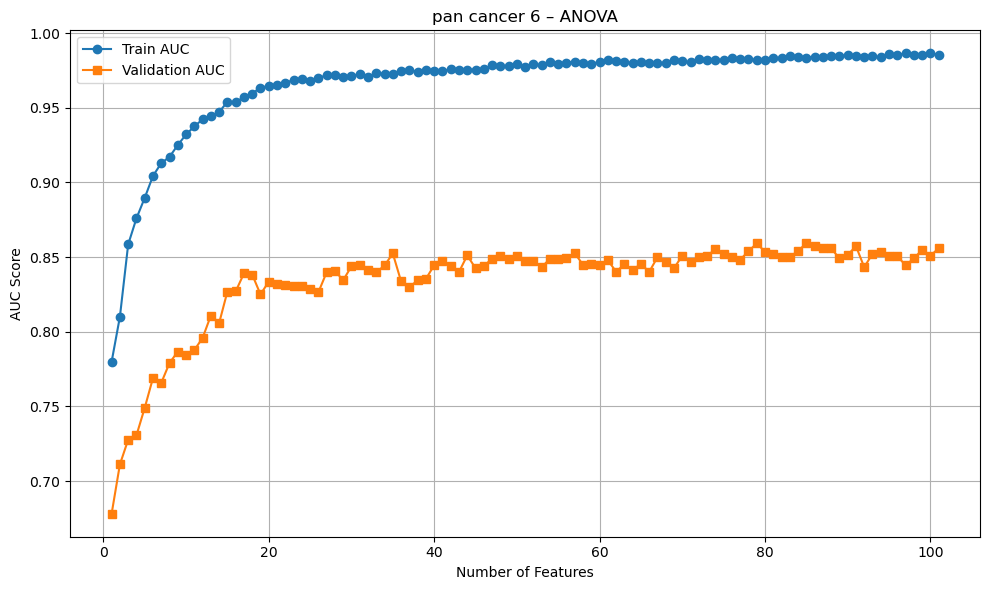

In [135]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取 CSV 文件
auc_df = pd.read_csv("AUC_scores_ANOVA6.csv")

# 绘制图像
plt.figure(figsize=(10, 6))
plt.plot(auc_df["Num_Features"], auc_df["Train_AUC"], label='Train AUC', marker='o')
plt.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], label='Validation AUC', marker='s')

plt.xlabel("Number of Features")
plt.ylabel("AUC Score")
plt.title("pan cancer 6 – ANOVA")
plt.legend()
plt.grid(True)
plt.tight_layout()

# 保存图像为 PNG 文件
plt.savefig("AUC_vs_FeatureCount_ANOVA6.png", dpi=300)
plt.show()


### ReliefF

In [1]:
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
import matplotlib.pyplot as plt

file_path = "pan_sample_6_labeled_ReliefFSorted.csv"
data = pd.read_csv(file_path)

In [2]:
data

,class,MOTIF_END_TGCC,MOTIF_END_TGCT,TMD_243,MOTIF_END_TGAC,MOTIF_END_TGTT,GWFP_short_10:90000001-95000000,TMD_76,TMD_20,TMD_433,...,CNA_4:176000001-177000000,CNA_17:21000001-22000000,CNA_7:92000001-93000000,CNA_1:88000001-89000000,CNA_8:29000001-30000000,CNA_5:178000001-179000000,CNA_1:82000001-83000000,CNA_10:103000001-104000000,CNA_3:50000001-51000000,CNA_1:13000001-14000000
0,1,0.002984,0.004037,0.000000,0.003342,0.005855,0.659178,0.875000,0.000000,1.000000,...,0.986225,1.17240,1.043470,1.009400,0.958483,1.10171,1.073320,0.980763,0.923782,0.967960
1,1,0.002996,0.004007,0.141304,0.003321,0.005544,0.470922,0.642857,0.175000,0.909091,...,0.989855,1.31340,0.990855,1.019660,0.941977,1.14077,0.996631,0.959531,0.939409,0.970525
2,1,0.002989,0.004105,0.200000,0.003449,0.005921,0.362080,1.000000,0.388889,1.000000,...,0.953984,1.22821,1.003990,1.013320,1.027520,1.08721,1.016200,0.981974,0.933925,0.965195
3,1,0.003072,0.004128,0.000000,0.003419,0.005900,0.325731,1.000000,0.000000,0.928571,...,0.962531,1.24638,1.033800,1.021250,0.925225,1.10878,1.010110,1.008370,0.941600,0.925010
4,1,0.002767,0.003717,0.325581,0.003307,0.005610,0.595310,0.882353,0.000000,0.500000,...,0.951999,1.21698,1.024710,1.039590,0.967780,1.13181,1.050280,0.971476,0.900526,1.255090
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1461,0,0.003569,0.004845,0.289474,0.003666,0.006595,1.100660,0.600000,0.103448,0.909091,...,0.941864,1.36303,1.002620,0.999414,0.942629,1.17804,0.996879,1.009040,0.931110,0.990193
1462,0,0.003175,0.004354,0.000000,0.003396,0.006009,0.984106,0.000000,0.250000,0.800000,...,1.009970,1.27669,1.029830,1.007390,0.975139,1.11313,1.044030,0.992010,0.881693,1.015050
1463,0,0.003589,0.004767,0.000000,0.003636,0.006439,0.247421,0.833333,0.176471,0.818182,...,0.946690,1.30308,1.021950,0.999159,0.931922,1.16216,1.008970,0.961547,0.887121,0.994022
1464,0,0.003399,0.004658,0.352941,0.003473,0.006313,0.854824,1.000000,0.400000,0.833333,...,0.978800,1.28928,1.000200,0.967665,0.974660,1.09791,1.035940,0.986397,0.932837,1.031270


In [3]:
# 分离特征和标签
X = data.drop(columns=['class'])  # 特征列
y = data['class']  # 标签列

# 数据分割：将数据集分为训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [4]:
all_features = X_train.columns.tolist()
auc_train_scores_ReliefF = []
auc_val_scores_ReliefF = []
best_auc = 0
best_feature_count = 0
best_X_train = None
best_X_test = None
best_X_val = None
prev_val_auc = 0
max_auc_diff = 0.1

# 连续超过阈值的计数器
overfit_count = 0
decline_count = 0

# 设置连续次数阈值
max_overfit_tolerance = 10
max_decline_tolerance = 5

In [5]:
for i in range(1, len(all_features) + 1):
    selected_features = all_features[:i]  # 前 i 个特征

    # # 计算样本权重（基于训练集）
    # classes = np.unique(y_train)
    # class_weights = compute_class_weight('balanced', classes=classes, y=y_train)
    # sample_weights = np.array([class_weights[i] for i in y_train])

    # 构造 DMatrix 数据
    dtrain = xgb.DMatrix(X_train[selected_features], label=y_train)
    dval = xgb.DMatrix(X_val[selected_features], label=y_val)
    dtest = xgb.DMatrix(X_test[selected_features], label=y_test)

    # 多分类 XGBoost 参数
    params = {
        'booster': 'gbtree',
        'objective': 'multi:softprob',   # 输出每类概率
        'num_class': 6,                  # 六分类
        'eval_metric': 'mlogloss',
        'max_depth': 4,
        'lambda': 3,
        'alpha': 0.2,
        'subsample': 0.75,
        'colsample_bytree': 0.75,
        'min_child_weight': 6,
        # 'eta': 0.025,
        'seed': 0,
        'nthread': 8,
        'gamma': 0.2,
        'learning_rate': 0.05
    }

    watchlist = [(dtrain, 'train'), (dval, 'eval')]

    # 模型训练
    model = xgb.train(params, dtrain, num_boost_round=50, evals=watchlist, early_stopping_rounds=10, verbose_eval=False)

    # 获取预测概率
    y_pred_train_prob = model.predict(dtrain)
    y_pred_val_prob = model.predict(dval)

    # AUC（One-vs-Rest 多分类）
    auc_train = roc_auc_score(y_train, y_pred_train_prob, multi_class='ovr', average='weighted')
    auc_val = roc_auc_score(y_val, y_pred_val_prob, multi_class='ovr', average='weighted')

    # 记录分数
    auc_train_scores_ReliefF.append(auc_train)
    auc_val_scores_ReliefF.append(auc_val)

    print(f"当前特征数: {i} | Val AUC: {auc_val:.4f}, Train AUC: {auc_train:.4f}")

    if i >100:
        break

    # 过拟合判断
    if (auc_train - auc_val) > max_auc_diff:
        overfit_count += 1
        print(f"过拟合检测：训练集 AUC={auc_train:.4f}, 验证集 AUC={auc_val:.4f}，连续次数：{overfit_count}")
        if overfit_count >= max_overfit_tolerance:
            print(f"过拟合连续超过 {max_overfit_tolerance} 次，停止特征增加！")
            break
    else:
        overfit_count = 0

    # 验证集 AUC 下降判断
    if auc_val < prev_val_auc:
        decline_count += 1
        print(f"验证集 AUC 开始下降（{prev_val_auc:.4f} → {auc_val:.4f}），连续次数：{decline_count}")
        if decline_count >= max_decline_tolerance:
            print(f"验证集 AUC 连续下降超过 {max_decline_tolerance} 次，停止特征增加！")
            break
    else:
        decline_count = 0

   # 记录当前最优特征集
    if auc_val > best_auc:
        best_auc = auc_val
        train_p = auc_train
        best_feature_count = i
        best_X_train = X_train[selected_features].copy()
        best_X_test = X_test[selected_features].copy()
        best_X_val = X_val[selected_features].copy()
        
    # 记录上一次的验证集 AUC
    prev_val_auc = auc_val

# 输出最佳特征数
print(f"选择的特征数: {best_feature_count}, 最佳验证集 AUC: {best_auc:.4f}, 对应的训练集 AUC：{train_p:.4f}")

当前特征数: 1 | Val AUC: 0.7051, Train AUC: 0.7734
当前特征数: 2 | Val AUC: 0.7206, Train AUC: 0.8015
当前特征数: 3 | Val AUC: 0.7820, Train AUC: 0.8594
当前特征数: 4 | Val AUC: 0.8066, Train AUC: 0.8840
当前特征数: 5 | Val AUC: 0.8175, Train AUC: 0.8941
当前特征数: 6 | Val AUC: 0.8238, Train AUC: 0.9091
当前特征数: 7 | Val AUC: 0.8353, Train AUC: 0.9204
当前特征数: 8 | Val AUC: 0.8384, Train AUC: 0.9260
当前特征数: 9 | Val AUC: 0.8500, Train AUC: 0.9333
当前特征数: 10 | Val AUC: 0.8440, Train AUC: 0.9396
验证集 AUC 开始下降（0.8500 → 0.8440），连续次数：1
当前特征数: 11 | Val AUC: 0.8489, Train AUC: 0.9407
当前特征数: 12 | Val AUC: 0.8603, Train AUC: 0.9470
当前特征数: 13 | Val AUC: 0.8593, Train AUC: 0.9463
验证集 AUC 开始下降（0.8603 → 0.8593），连续次数：1
当前特征数: 14 | Val AUC: 0.8610, Train AUC: 0.9477
当前特征数: 15 | Val AUC: 0.8701, Train AUC: 0.9535
当前特征数: 16 | Val AUC: 0.8747, Train AUC: 0.9589
当前特征数: 17 | Val AUC: 0.8768, Train AUC: 0.9610
当前特征数: 18 | Val AUC: 0.8767, Train AUC: 0.9616
验证集 AUC 开始下降（0.8768 → 0.8767），连续次数：1
当前特征数: 19 | Val AUC: 0.8784, Train AUC: 0.9639
当前特征数

In [ ]:
pan_sample_ReliefFSorted = pd.read_csv("pan_sample_6_labeled_ReliefFSorted.csv")
pan_sample_ReliefFSorted_selected42 = pan_sample_ReliefFSorted.iloc[:, :43]
pan_sample_ReliefFSorted_selected42.to_csv("../ReliefF/pan_sample_6_labeled_ReliefFSorted_selected42.csv", index=False)

In [25]:
import pandas as pd

# 保存训练集和验证集的 AUC 到 CSV
auc_df = pd.DataFrame({
    "Num_Features": range(1, len(auc_train_scores_ReliefF) + 1),
    "Train_AUC": auc_train_scores_ReliefF,
    "Validation_AUC": auc_val_scores_ReliefF
})

auc_df.to_csv("AUC_scores_ReliefF6.csv", index=False)

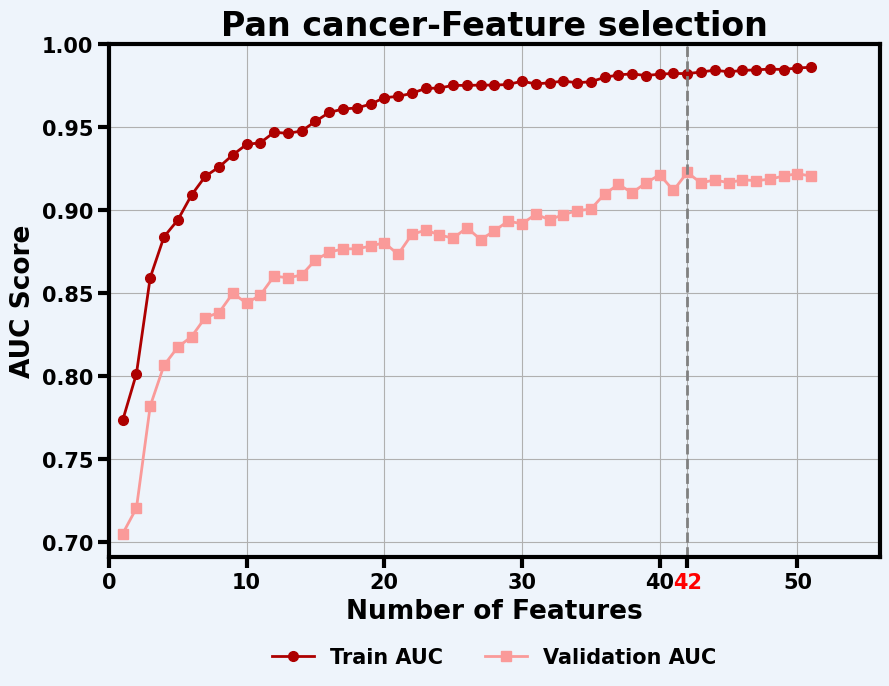

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取 CSV 文件
auc_df = pd.read_csv("AUC_scores_ReliefF6.csv")

# 绘制图像
plt.figure(figsize=(9, 7))
plt.plot(auc_df["Num_Features"], auc_df["Train_AUC"], label='Train AUC', marker='o', linewidth=2, markersize=7, color='#ad0000')
plt.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], label='Validation AUC', marker='s', linewidth=2, markersize=7, color='#fa9a99')

plt.xlabel("Number of Features", fontsize=19, fontweight='bold')
plt.ylabel("AUC Score", fontsize=19, fontweight='bold')
plt.title("Pan cancer-Feature selection", fontsize=24, fontweight='bold')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False, prop={'family': 'sans-serif', 'size': 15, 'weight': 'bold'})
plt.grid(True)

# 添加竖线标注特征数 = 42
plt.axvline(x=42, color='gray', linestyle='--', linewidth=2)

# 设置 x 轴刻度并强制包含 42
xticks = sorted(set(plt.xticks()[0].tolist() + [42]))
plt.xticks(xticks)

# 获取坐标轴并标红 42
ax = plt.gca()
for label in ax.get_xticklabels():
    if label.get_text() == '42':
        label.set_color('red')

ax.set_xlim(left=0, right=max(auc_df["Num_Features"]) + 5)

ax = plt.gca()  # 获取当前坐标轴
for spine in ax.spines.values():
    spine.set_linewidth(3)
ax.tick_params(axis='both', width=3, length=8)
for tick_label in ax.get_xticklabels() + ax.get_yticklabels():
    tick_label.set_fontsize(15)
    tick_label.set_fontweight('bold')

# 保存图像为 PNG 文件
plt.tight_layout()
plt.savefig("AUC_vs_FeatureCount_ReliefF_pan6.png", dpi=300)
plt.show()


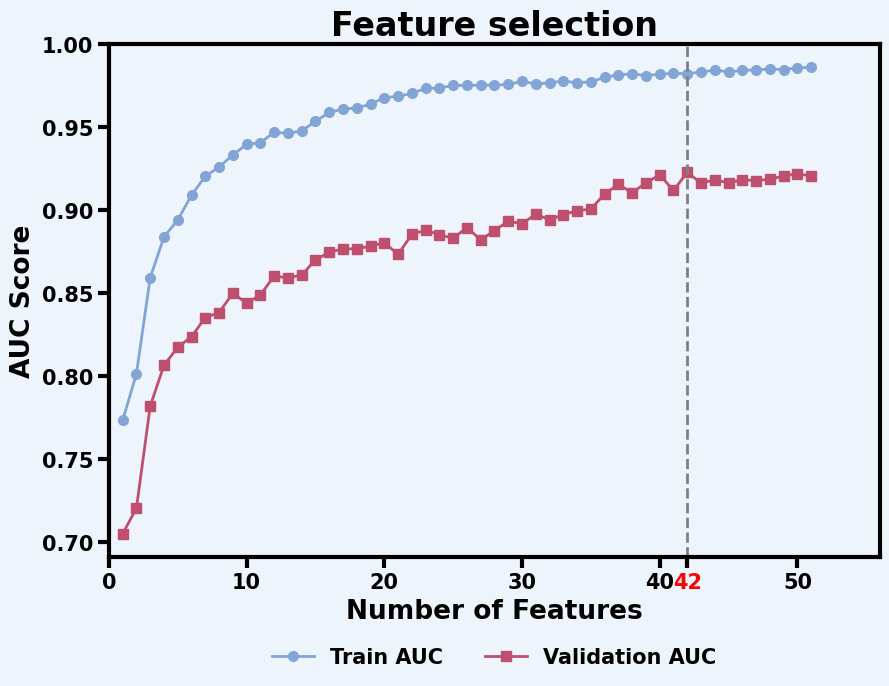

In [6]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取 CSV 文件
auc_df = pd.read_csv("AUC_scores_ReliefF6.csv")

# ===== 背景色设置 =====
bg_color = '#eef4fb'
plt.rcParams['figure.facecolor']    = bg_color
plt.rcParams['axes.facecolor']      = bg_color
plt.rcParams['savefig.facecolor']   = bg_color
plt.rcParams['savefig.transparent'] = False

# 绘制图像
plt.figure(figsize=(9, 7))
plt.plot(auc_df["Num_Features"], auc_df["Train_AUC"], label='Train AUC',
        marker='o', linewidth=2, markersize=7, color='#82a5d6')
plt.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], label='Validation AUC',
        marker='s', linewidth=2, markersize=7, color='#bf4f6f')

plt.xlabel("Number of Features", fontsize=19, fontweight='bold')
plt.ylabel("AUC Score", fontsize=19, fontweight='bold')
plt.title("Feature selection", fontsize=24, fontweight='bold')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2,
        frameon=False, prop={'family': 'sans-serif', 'size': 15, 'weight': 'bold'})

# 去掉背景网格
plt.grid(False)

# 添加竖线标注特征数 = 42
plt.axvline(x=42, color='gray', linestyle='--', linewidth=2)

# 设置 x 轴刻度并强制包含 42
xticks = sorted(set(plt.xticks()[0].tolist() + [42]))
plt.xticks(xticks)

# 获取坐标轴并标红 42
ax = plt.gca()
for label in ax.get_xticklabels():
        if label.get_text() == '42':
                label.set_color('red')

# 坐标轴范围
ax.set_xlim(left=0, right=max(auc_df["Num_Features"]) + 5)

# 轴样式（保持不变）
for spine in ax.spines.values():
        spine.set_linewidth(3)
ax.tick_params(axis='both', width=3, length=8)
for tick_label in ax.get_xticklabels() + ax.get_yticklabels():
        tick_label.set_fontsize(15)
        tick_label.set_fontweight('bold')

# 保存图像为 PNG 文件（确保导出也带背景色）
plt.tight_layout()
plt.savefig("FeatureCount.png", dpi=300, facecolor=bg_color)
plt.show()


### Binomial

In [157]:
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
import matplotlib.pyplot as plt

file_path = "pan_sample_6_labeled_BinomialSorted.csv"
data = pd.read_csv(file_path)

In [158]:
data

,class,TMD_83,TMD_148,TMD_218,TMD_303,GWMD_chr10_11,GWMD_chr5_165,flen_151,flen_150,flen_152,...,GWFP_long_6:60000001-65000000,CNA_5:124000001-125000000,CNA_3:66000001-67000000,CNA_2:174000001-175000000,CNA_5:68000001-69000000,GWFP_total_11:85000001-90000000,CNA_1:15000001-16000000,GWFP_short_9:65000001-70000000,GWFP_short_12:20000001-25000000,CNA_12:44000001-45000000
0,1,1.000000,1.0,0.714286,0.96,0.846917,0.843318,0.012706,0.012248,0.013033,...,-0.879303,1.02026,1.04578,0.980188,1.040990,-0.190641,1.028650,-1.26354,0.727913,0.981253
1,1,0.906250,1.0,1.000000,1.00,0.852679,0.837666,0.012889,0.012420,0.013470,...,-0.835127,1.04302,1.07397,0.985508,0.963551,-0.216460,1.055700,-1.30064,0.562265,0.999383
2,1,1.000000,1.0,1.000000,1.00,0.860036,0.857406,0.012243,0.011807,0.012692,...,-0.834712,1.02951,1.06203,0.986758,0.979467,-0.165502,1.075610,-1.30088,0.795535,0.969621
3,1,0.961538,1.0,0.833333,1.00,0.877633,0.884478,0.011246,0.010824,0.011777,...,-0.952423,1.06507,1.07144,0.997434,0.974097,-0.136375,1.050040,-1.16856,0.771068,0.944849
4,1,1.000000,1.0,1.000000,1.00,0.808961,0.852210,0.014603,0.014315,0.014815,...,-1.058110,1.04319,1.03557,0.857191,0.958841,-0.339847,1.074790,-1.14009,0.766254,0.987796
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1308,0,1.000000,1.0,1.000000,1.00,0.879876,0.862667,0.013753,0.013310,0.014163,...,-0.954953,1.01168,1.03553,0.966014,0.981062,-0.046056,1.039330,-1.16317,0.674901,1.009260
1309,0,1.000000,1.0,0.000000,1.00,0.869067,0.859594,0.010695,0.010386,0.011133,...,-0.752148,1.10116,1.05775,1.000740,1.030890,-0.129995,1.003690,-1.14975,0.783945,0.975904
1310,0,1.000000,1.0,0.000000,1.00,0.865953,0.837747,0.014248,0.014182,0.014608,...,-0.848213,1.03963,1.02998,0.965419,1.028190,-0.155697,1.051640,-1.29776,0.469207,0.991012
1311,0,1.000000,1.0,0.857143,1.00,0.860819,0.860410,0.012230,0.011908,0.012683,...,-0.855094,1.01878,1.07766,0.992775,1.013310,-0.176559,1.033170,-1.09012,0.553260,1.024120


In [159]:
# 分离特征和标签
X = data.drop(columns=['class'])  # 特征列
y = data['class']  # 标签列

# 数据分割：将数据集分为训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [160]:
all_features = X_train.columns.tolist()
auc_train_scores_Binomial = []
auc_val_scores_Binomial = []
best_auc = 0
best_feature_count = 0
best_X_train = None
best_X_test = None
best_X_val = None
prev_val_auc = 0
max_auc_diff = 0.2

# 连续超过阈值的计数器
overfit_count = 0
decline_count = 0

# 设置连续次数阈值
max_overfit_tolerance = 15
max_decline_tolerance = 5

In [161]:
for i in range(1, len(all_features) + 1):
    selected_features = all_features[:i]  # 前 i 个特征

    # # 计算样本权重（基于训练集）
    # classes = np.unique(y_train)
    # class_weights = compute_class_weight('balanced', classes=classes, y=y_train)
    # sample_weights = np.array([class_weights[i] for i in y_train])

    # 构造 DMatrix 数据
    dtrain = xgb.DMatrix(X_train[selected_features], label=y_train)
    dval = xgb.DMatrix(X_val[selected_features], label=y_val)
    dtest = xgb.DMatrix(X_test[selected_features], label=y_test)

    # 多分类 XGBoost 参数
    params = {
        'booster': 'gbtree',
        'objective': 'multi:softprob',   # 输出每类概率
        'num_class': 6,                  # 六分类
        'eval_metric': 'mlogloss',
        'max_depth': 4,
        'lambda': 3,
        'alpha': 0.2,
        'subsample': 0.75,
        'colsample_bytree': 0.75,
        'min_child_weight': 6,
        # 'eta': 0.025,
        'seed': 0,
        'nthread': 8,
        'gamma': 0.2,
        'learning_rate': 0.05
    }

    watchlist = [(dtrain, 'train'), (dval, 'eval')]

    # 模型训练
    model = xgb.train(params, dtrain, num_boost_round=50, evals=watchlist, early_stopping_rounds=10, verbose_eval=False)

    # 获取预测概率
    y_pred_train_prob = model.predict(dtrain)
    y_pred_val_prob = model.predict(dval)

    # AUC（One-vs-Rest 多分类）
    auc_train = roc_auc_score(y_train, y_pred_train_prob, multi_class='ovr', average='weighted')
    auc_val = roc_auc_score(y_val, y_pred_val_prob, multi_class='ovr', average='weighted')

    # 记录分数
    auc_train_scores_Binomial.append(auc_train)
    auc_val_scores_Binomial.append(auc_val)

    print(f"当前特征数: {i} | Val AUC: {auc_val:.4f}, Train AUC: {auc_train:.4f}")

    if i >200:
        break

    # 过拟合判断
    if (auc_train - auc_val) > max_auc_diff:
        overfit_count += 1
        print(f"过拟合检测：训练集 AUC={auc_train:.4f}, 验证集 AUC={auc_val:.4f}，连续次数：{overfit_count}")
        if overfit_count >= max_overfit_tolerance:
            print(f"过拟合连续超过 {max_overfit_tolerance} 次，停止特征增加！")
            break
    else:
        overfit_count = 0

    # 验证集 AUC 下降判断
    if auc_val < prev_val_auc:
        decline_count += 1
        print(f"验证集 AUC 开始下降（{prev_val_auc:.4f} → {auc_val:.4f}），连续次数：{decline_count}")
        if decline_count >= max_decline_tolerance:
            print(f"验证集 AUC 连续下降超过 {max_decline_tolerance} 次，停止特征增加！")
            break
    else:
        decline_count = 0

   # 记录当前最优特征集
    if auc_val > best_auc:
        best_auc = auc_val
        train_p = auc_train
        best_feature_count = i
        best_X_train = X_train[selected_features].copy()
        best_X_test = X_test[selected_features].copy()
        best_X_val = X_val[selected_features].copy()
        
    # 记录上一次的验证集 AUC
    prev_val_auc = auc_val

# 输出最佳特征数
print(f"选择的特征数: {best_feature_count}, 最佳验证集 AUC: {best_auc:.4f}, 对应的训练集 AUC：{train_p:.4f}")

当前特征数: 1 | Val AUC: 0.5763, Train AUC: 0.6645
当前特征数: 2 | Val AUC: 0.6465, Train AUC: 0.7353
当前特征数: 3 | Val AUC: 0.6898, Train AUC: 0.7920
当前特征数: 4 | Val AUC: 0.7226, Train AUC: 0.8322
当前特征数: 5 | Val AUC: 0.7634, Train AUC: 0.8776
当前特征数: 6 | Val AUC: 0.7827, Train AUC: 0.8899
当前特征数: 7 | Val AUC: 0.7932, Train AUC: 0.9088
当前特征数: 8 | Val AUC: 0.7979, Train AUC: 0.9131
当前特征数: 9 | Val AUC: 0.7904, Train AUC: 0.9151
验证集 AUC 开始下降（0.7979 → 0.7904），连续次数：1
当前特征数: 10 | Val AUC: 0.7897, Train AUC: 0.9233
验证集 AUC 开始下降（0.7904 → 0.7897），连续次数：2
当前特征数: 11 | Val AUC: 0.8058, Train AUC: 0.9282
当前特征数: 12 | Val AUC: 0.8137, Train AUC: 0.9342
当前特征数: 13 | Val AUC: 0.8179, Train AUC: 0.9389
当前特征数: 14 | Val AUC: 0.8292, Train AUC: 0.9409
当前特征数: 15 | Val AUC: 0.8238, Train AUC: 0.9429
验证集 AUC 开始下降（0.8292 → 0.8238），连续次数：1
当前特征数: 16 | Val AUC: 0.8261, Train AUC: 0.9454
当前特征数: 17 | Val AUC: 0.8178, Train AUC: 0.9499
验证集 AUC 开始下降（0.8261 → 0.8178），连续次数：1
当前特征数: 18 | Val AUC: 0.8140, Train AUC: 0.9503
验证集 AUC 开始下降（0.

In [165]:
pan_sample_BinomialSorted = pd.read_csv("pan_sample_6_labeled_BinomialSorted.csv")
pan_sample_BinomialSorted_selected150 = pan_sample_BinomialSorted.iloc[:, :151]
pan_sample_BinomialSorted_selected150.to_csv("../Binomial/pan_sample_6_labeled_BinomialSorted_selected150.csv", index=False)

In [162]:
import pandas as pd

# 保存训练集和验证集的 AUC 到 CSV
auc_df = pd.DataFrame({
    "Num_Features": range(1, len(auc_train_scores_Binomial) + 1),
    "Train_AUC": auc_train_scores_Binomial,
    "Validation_AUC": auc_val_scores_Binomial
})

auc_df.to_csv("AUC_scores_Binomial6.csv", index=False)

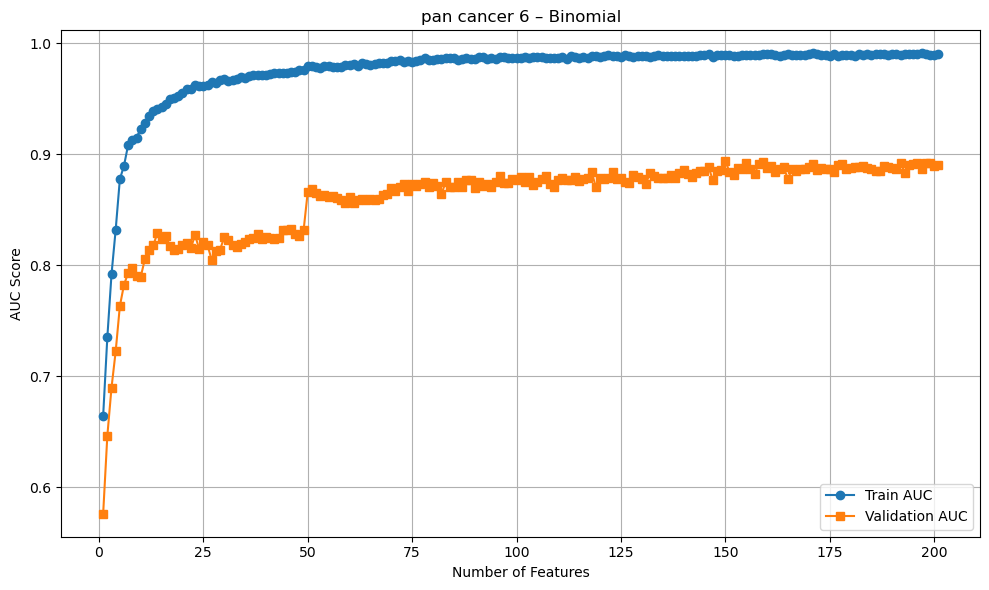

In [163]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取 CSV 文件
auc_df = pd.read_csv("AUC_scores_Binomial6.csv")

# 绘制图像
plt.figure(figsize=(10, 6))
plt.plot(auc_df["Num_Features"], auc_df["Train_AUC"], label='Train AUC', marker='o')
plt.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], label='Validation AUC', marker='s')

plt.xlabel("Number of Features")
plt.ylabel("AUC Score")
plt.title("pan cancer 6 – Binomial")
plt.legend()
plt.grid(True)
plt.tight_layout()

# 保存图像为 PNG 文件
plt.savefig("AUC_vs_FeatureCount_Binomial6.png", dpi=300)
plt.show()